# 과제 4 — MovieLens 1M 스트리밍 알고리즘 비교: CMS v2 재실험 및 최종 결과 통합

이 파일은 Colab 노트북(`MovieLens_1M_CMS_v2_Rerun.ipynb`)과 GitHub 소스(`movielens_streaming.py`)의 공통 원본이다.
두 파일의 파라미터와 알고리즘 구현은 같다.

| 구분 | 처리 |
|---|---|
| Bloom 정확도·파라미터 15개·포화 실험, Set 메모리·처리시간, 데이터 탐색 | **v1 결과 재사용** (`movielens_results.zip`, 같은 v1 런타임에서 측정) |
| CMS v2 (mix64 사전 혼합) 9개 설정의 정확도·메모리·처리시간 | **이번 실행(v2)에서 측정** |
| 파싱·Dictionary 처리시간과 메모리 | **이번 실행(v2)에서 측정** (CMS와 같은 런타임 비교) |

- 원본 파일 순서대로 재생하는 스트림이며, 실시간·시간순 스트림이라고 주장하지 않는다.
- 서로 다른 런타임의 처리시간은 직접 비교하지 않는다 (Bloom↔Set은 v1, CMS↔Dictionary는 v2).
- CMS v1(선형 해시) 결과는 `archive_v1/`에 보관만 하고 본 결과와 섞지 않는다.
- 기존 `movielens_results.zip`은 수정하지 않고 `movielens_results_final.zip`을 새로 만든다.

**실행 (Colab)**: 런타임 → 모두 실행. 업로드 창이 뜨면 1차 실행 결과 `movielens_results.zip`을 선택한다.
**실행 (로컬)**: `movielens_results.zip`을 같은 폴더에 두고 `python movielens_streaming.py`

In [2]:
# ===== 설정 =====
from pathlib import Path
from collections import Counter
from array import array
import csv, gc, hashlib, json, math, os, platform, random, shutil, statistics, subprocess, sys, time, zipfile

URL = 'https://files.grouplens.org/datasets/movielens/ml-1m.zip'   # 교수님 제공 공식 URL
RAW = Path('ml-1m/ratings.dat')
V1_ZIP = Path('movielens_results.zip')          # 1차 실행 결과 (읽기만 함)
V1_DIR = Path('results_movielens_v1')
V2_DIR = Path('results_movielens_v2')           # 이번 실행 원자료 (중간 저장)
FINAL_DIR = Path('results_movielens_final')
FINAL_ZIP = Path('movielens_results_final.zip') # v1 ZIP과 다른 이름

EXPECTED = 1_000_209
MASK = (1 << 64) - 1
PRIME = (1 << 61) - 1
SEEDS = (42, 123, 2026)          # v1과 동일. 추가 시드(123, 2026)는 대표 설정에서만 사용
FPR_TARGET = 0.01                # 실험용 가정 (산업 표준 아님)
CMS_HIGH_FREQ_RE_TARGET = 0.05   # 빈도 100 이상 영화의 평균 상대오차 (실험용 가정)
CMS_TOP100_TARGET = 0.95         # Top-100 일치율 (실험용 가정)

# ----- CMS 최종 파라미터 9개 (확정) -----
CMS_REF = (2719, 5)              # 대표 설정: eps = e/w ≈ 0.001, delta = e^-5 ≈ 0.007
CMS_CONFIGS = [
    (124, 5), (371, 5), (1235, 5), (2719, 5), (15000, 5),   # 너비 효과 (d = 5 고정)
    (371, 1), (371, 8),                                     # 깊이 효과 (w = 371 고정, (371,5) 포함)
    (1855, 1), (13595, 1),                                  # 동일 메모리 비교 상대 (d = 1)
]
EQUAL_MEMORY_PAIRS = [((1855, 1), (371, 5)), ((13595, 1), (2719, 5))]   # 카운터 수 동일: 1855개, 13595개
REPS_REF, REPS_OTHER, REPS_BASE = 3, 1, 3   # 대표 설정 3회, 나머지 1회, 파싱·Dictionary 3회

ALLOW_DATA_MISMATCH = False      # 데이터 SHA-256이 v1과 다르면 중단 (테스트 외에는 False 유지)
assert array('I').itemsize == 4
assert len(CMS_CONFIGS) == 9 and CMS_REF in CMS_CONFIGS
assert all(a[0] * a[1] == b[0] * b[1] for a, b in EQUAL_MEMORY_PAIRS)
T_START = time.perf_counter()
def elapsed(): return f'{(time.perf_counter() - T_START) / 60:5.1f}분'

In [3]:
# ===== 공통 코드 (v1과 동일한 데이터 읽기, Bloom Filter, 정답 구조, 측정 함수) =====
def ensure_data():
    if RAW.is_file():
        print('기존 데이터 재사용:', RAW, flush=True); return
    temp = Path('ml-1m.zip.part')
    try:
        print('공식 URL에서 다운로드:', URL, flush=True)
        subprocess.run(['curl', '-fL', '--connect-timeout', '10', '--max-time', '120', URL, '-o', str(temp)], check=True)
        with zipfile.ZipFile(temp) as z:
            z.extract('ml-1m/ratings.dat')
    finally:
        temp.unlink(missing_ok=True)
    print('다운로드 및 압축 해제 완료', flush=True)

def events(path):
    """ratings.dat 을 한 줄씩 읽어 (user, movie, rating, timestamp) 를 내보낸다 (스트리밍)."""
    with Path(path).open(encoding='ascii') as f:
        for lineno, line in enumerate(f, 1):
            try:
                u, i, r, t = map(int, line.rstrip('\r\n').split('::'))
                if not (u > 0 and i > 0 and 1 <= r <= 5 and t > 0 and u < 2**32 and i < 2**32):
                    raise ValueError('범위 오류')
            except ValueError as exc:
                raise ValueError(f'잘못된 레코드 {lineno}: {exc}') from exc
            yield u, i, r, t

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda: f.read(1 << 20), b''): h.update(b)
    return h.hexdigest()

def mix64(x):
    x &= MASK
    x = ((x ^ (x >> 30)) * 0xbf58476d1ce4e5b9) & MASK
    x = ((x ^ (x >> 27)) * 0x94d049bb133111eb) & MASK
    return x ^ (x >> 31)

class BloomFilter:
    """Bloom Filter (v1과 동일, 결과는 v1 실행에서 측정). bytearray 비트 배열 + mix64 2개 double hashing."""
    def __init__(self, m, k, seed=42):
        self.m = int(m); self.k = int(k)
        assert self.m > 0 and self.k > 0
        rng = random.Random(seed)
        self.s1 = rng.getrandbits(64); self.s2 = rng.getrandbits(64)
        self.bits = bytearray((self.m + 7) // 8)
    def hashes(self, key):
        u, i = key; x = (u << 32) | i
        return mix64(x ^ self.s1), mix64(x ^ self.s2) | 1
    def add(self, key):
        h, g = self.hashes(key); a = h % self.m; step = g % self.m
        for _ in range(self.k):
            self.bits[a >> 3] |= 1 << (a & 7)
            a = (a + step) % self.m
    def query(self, key):
        h, g = self.hashes(key); a = h % self.m; step = g % self.m
        for _ in range(self.k):
            if not (self.bits[a >> 3] & (1 << (a & 7))): return False
            a = (a + step) % self.m
        return True
    def fill(self): return sum(x.bit_count() for x in self.bits) / self.m
    def payload(self): return len(self.bits)

class ExactSet:
    def __init__(self): self.data = set()
    def add(self, k): self.data.add(k)
    def query(self, k): return k in self.data

class ExactDict:
    def __init__(self): self.data = {}
    def add(self, k): self.data[k] = self.data.get(k, 0) + 1
    def query(self, k): return self.data.get(k, 0)

def deep_size(obj):
    """sys.getsizeof 기반 Python 객체 크기 추정 (참조 객체 포함)."""
    seen = set(); stack = [obj]; total = 0
    while stack:
        x = stack.pop(); oid = id(x)
        if oid in seen: continue
        seen.add(oid); total += sys.getsizeof(x)
        if isinstance(x, dict):
            for k, v in x.items(): stack.append(k); stack.append(v)
        elif isinstance(x, (set, list, tuple)): stack.extend(x)
        elif hasattr(x, '__dict__'): stack.append(vars(x))
    return total

def inspect_counts(path, expected=EXPECTED):
    """데이터 검증 + 영화별 정확 빈도(CMS 정답). Bloom을 다시 측정하지 않으므로 조합 Set은 만들지 않는다."""
    counts = {}; users_max = 0; N = 0
    for u, i, r, t in events(path):
        N += 1; counts[i] = counts.get(i, 0) + 1; users_max = max(users_max, u)
    if expected is not None and N != expected: raise ValueError(f'공식 레코드 수 불일치: {N}')
    return {'records': N, 'movies': len(counts), 'max_user_id': users_max, 'max_movie_id': max(counts),
            'sha256': sha256(path), 'size_bytes': Path(path).stat().st_size, 'source': URL}, counts

def stream_update(state, kind, path):
    add = state.add
    if kind == 'bf':
        for u, i, r, t in events(path): add((u, i))
    else:
        for u, i, r, t in events(path): add(i)

def stream_update_many(states, path):
    """정확도 전용: 대표 설정의 추가 시드 CMS를 한 번의 읽기로 함께 갱신 (시간 측정에 사용하지 않음)."""
    adds = [s.add for s in states]
    for u, i, r, t in events(path):
        for a in adds: a(i)

def timing_stats(times, N):
    t = statistics.median(times)
    q = statistics.quantiles(times, n=4, method='inclusive') if len(times) > 1 else [t, t, t]
    return {'update_seconds': t, 'time_iqr_seconds': q[2] - q[0] if len(times) > 1 else None,
            'throughput_records_s': N / t, 'timing_repeats': len(times),
            'all_update_seconds': json.dumps([round(x, 4) for x in times])}

def timed_build(factory, kind, path, N, repeats):
    times = []
    for j in range(repeats):
        gc.collect(); state = factory(); t = time.perf_counter(); stream_update(state, kind, path)
        times.append(time.perf_counter() - t)
        if j + 1 < repeats: del state
    return state, timing_stats(times, N)

BANDS = [('1-5', 1, 5), ('6-49', 6, 49), ('50-99', 50, 99), ('100+', 100, float('inf'))]

def cms_accuracy(state, truth, N):
    t = time.perf_counter(); estimate = {i: state.query(i) for i in truth}; el = time.perf_counter() - t
    errors = {i: estimate[i] - v for i, v in truth.items()}
    under = sum(e < 0 for e in errors.values())
    assert under == 0, f'과소추정 {under}건 발생'
    actual_top = sorted(truth, key=lambda i: (-truth[i], i)); estimated_top = sorted(estimate, key=lambda i: (-estimate[i], i))
    def top(k):
        k = min(k, len(truth)); return len(set(actual_top[:k]) & set(estimated_top[:k])) / k
    eps = math.e / state.w; delta = math.exp(-state.d)
    row = {'mae': statistics.mean(errors.values()), 'max_error': max(errors.values()), 'underestimates': under,
           'exact_fraction': sum(e == 0 for e in errors.values()) / len(truth),
           'mean_relative_error': statistics.mean(errors[i] / truth[i] for i in truth),
           'top10_precision': top(10), 'top100_precision': top(100), 'epsilon': eps, 'delta': delta,
           'eps_N': eps * N, 'bound_satisfied_fraction': sum(e <= eps * N for e in errors.values()) / len(truth),
           'single_row_expected_collision_approx': (N - N / len(truth)) / state.w,
           'query_seconds': el, 'query_throughput_s': len(truth) / el}
    bands = []
    for label, lo, hi in BANDS:
        ids = [i for i, v in truth.items() if lo <= v <= hi]
        bands.append({'frequency_band': label, 'items': len(ids),
                      'mae': statistics.mean(errors[i] for i in ids) if ids else None,
                      'mean_relative_error': statistics.mean(errors[i] / truth[i] for i in ids) if ids else None})
    row['high_freq_mean_relative_error'] = bands[-1]['mean_relative_error']
    return row, bands

def save_json(folder, name, obj):
    Path(folder).mkdir(parents=True, exist_ok=True)
    (Path(folder) / name).write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False, default=str), encoding='utf-8')

def save_csv(folder, name, rows):
    if not rows: return
    Path(folder).mkdir(parents=True, exist_ok=True)
    with (Path(folder) / name).open('w', encoding='utf-8-sig', newline='') as f:
        w = csv.DictWriter(f, fieldnames=list(dict.fromkeys(k for r in rows for k in r)))
        w.writeheader(); w.writerows(rows)

def read_csv(path):
    def conv(v):
        if v in ('', None): return None
        if v in ('True', 'False'): return v == 'True'
        try: return int(v)
        except ValueError:
            try: return float(v)
            except ValueError: return v
    with Path(path).open(encoding='utf-8-sig') as f:
        return [{k: conv(v) for k, v in r.items()} for r in csv.DictReader(f)]

def wilson(k, n):
    p = k / n; z = 1.95996398454; den = 1 + z * z / n
    mid = (p + z * z / (2 * n)) / den; half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return max(0, mid - half), min(1, mid + half)

In [4]:
# ===== Count-Min Sketch v2 (최종 구현) =====
class CountMinSketch:
    """Count-Min Sketch v2 (mix64 사전 혼합 + 행별 선형 모듈러 해시, uint32 카운터).

    v1과의 차이: v1은 영화 ID(연속 정수)에 ((a*key+b) mod PRIME) mod w 를 바로 적용했다.
    연속 정수에 선형 해시를 쓰면 해시값이 등차수열이 되어 충돌 패턴이 시드에 따라
    무작위 해시보다 크게 좋거나 나빠졌다. v2는 키를 먼저 mix64(key XOR salt) mod PRIME 로
    섞은 뒤 같은 선형 해시를 적용한다. 삽입(add)과 조회(query)는 같은 _x()를 사용한다.

    (a, b)는 v1과 같은 시드·같은 순서로 생성하고 salt만 그 뒤에 추가로 뽑으므로,
    같은 시드에서 v1과 v2의 차이는 사전 혼합 유무뿐이다.

    이론적 보장의 적용 조건:
      1) 서로 다른 키가 서로 다른 x(0 <= x < PRIME)로 변환될 것 -> verify_cms_prehash()로 실제 ID 전체 확인
      2) 각 행의 (a, b)가 데이터와 무관하게 미리 정한 시드로 생성될 것 (a != 0)
      3) 삽입만 있는 스트림(카운트 증가만)일 것 -> 추정값 >= 실제값 (과소추정 없음)
    이 조건에서 x 위의 ((a*x+b) mod PRIME) mod w 는 (근사) universal 해시족이므로
    키마다 P(오차 > eps*N) <= delta, eps = e/w, delta = e^(-d) 가 (a, b)의 무작위성에 대해 성립한다.
    mix64는 무작위성을 추가하는 장치가 아니라 입력의 등차 구조를 깨는 고정된 단사 변환이다.
    """
    version = 'v2_mix64'

    def __init__(self, w, d, seed=42):
        self.w = int(w); self.d = int(d)
        assert self.w > 0 and self.d > 0
        rng = random.Random(seed)
        self.params = [(rng.randrange(1, PRIME), rng.randrange(PRIME)) for _ in range(self.d)]
        self.salt = rng.getrandbits(64)
        self.table = array('I', [0]) * (self.w * self.d)

    def _x(self, key):
        return mix64(key ^ self.salt) % PRIME

    def add(self, key):
        x = mix64(key ^ self.salt) % PRIME
        w = self.w; t = self.table
        for row, (a, b) in enumerate(self.params):
            t[row * w + ((a * x + b) % PRIME) % w] += 1

    def query(self, key):
        x = mix64(key ^ self.salt) % PRIME
        w = self.w; t = self.table
        return min(t[row * w + ((a * x + b) % PRIME) % w] for row, (a, b) in enumerate(self.params))

    def payload(self):
        return len(self.table) * self.table.itemsize


def verify_cms_prehash(ids, seeds):
    """실제 키 전체에 대해 사전 혼합 값 x가 모두 서로 다른지 확인 (이론 보장의 조건 1)."""
    ids = list(ids); out = []
    for seed in seeds:
        s = CountMinSketch(1, 1, seed)
        xs = [s._x(i) for i in ids]
        distinct = len(set(xs))
        out.append({'seed': seed, 'keys': len(ids), 'distinct_prehash': distinct,
                    'injective': distinct == len(ids), 'all_below_prime': max(xs) < PRIME})
        if distinct != len(ids):
            raise AssertionError(f'시드 {seed}: 사전 혼합 후 충돌 발생 ({len(ids) - distinct}건). 시드를 바꾸지 말고 보고할 것.')
    return out

def v1_linear_bucket(key, a, b, w):
    """진단 전용: v1 CMS의 행 해시 ((a*key+b) mod PRIME) mod w. 실험에는 사용하지 않는다."""
    return ((a * key + b) % PRIME) % w

def unit_tests():
    keys = [(1, 2), (2, 3), (1, 2), (10, 30)]
    b = BloomFilter(128, 4); c = CountMinSketch(4, 3); s = ExactSet(); d = ExactDict()
    for u, i in keys: b.add((u, i)); s.add((u, i)); c.add(i); d.add(i)
    assert all(b.query(x) for x in s.data)
    assert all(c.query(i) >= v for i, v in d.data.items())
    assert c.payload() == 48 and b.payload() == 16
    assert s.query((1, 2)) and not s.query((2, 1)) and d.query(2) == 2
    rng = random.Random(42); v1_params = [(rng.randrange(1, PRIME), rng.randrange(PRIME)) for _ in range(3)]
    assert CountMinSketch(10, 3, 42).params == v1_params          # v1과 같은 (a,b): 차이는 사전 혼합뿐
    c2 = CountMinSketch(7, 3, 123); truth = Counter(); rr = random.Random(0)
    for _ in range(5000):
        k = rr.randint(1, 3952); c2.add(k); truth[k] += 1
    assert all(c2.query(k) >= v for k, v in truth.items())       # 과소추정 없음
    assert all(sum(c2.table[r * 7:(r + 1) * 7]) == 5000 for r in range(3))   # 행 합계 = 삽입 수
    verify_cms_prehash(range(1, 3953), SEEDS)
    print('단위 테스트 통과 (CMS v2: v1과 같은 (a,b), 과소추정 없음, 행 합계 = 삽입 수, ID 1~3952 단사)')

In [5]:
# ===== 실행 환경 기록 =====
def env_info():
    info = {'python': sys.version, 'platform': platform.platform(), 'machine': platform.machine(),
            'cpu_count_logical': os.cpu_count()}
    try:
        with open('/proc/cpuinfo') as f:
            names = [l.split(':', 1)[1].strip() for l in f if l.startswith('model name')]
        info['cpu_model'] = names[0] if names else 'unknown'
    except OSError:
        info['cpu_model'] = platform.processor() or 'unknown'
    try:
        with open('/proc/meminfo') as f:
            for l in f:
                if l.startswith('MemTotal'): info['ram_gb'] = round(int(l.split()[1]) / 1024 / 1024, 2)
    except OSError:
        pass
    try:
        import matplotlib; info['matplotlib'] = matplotlib.__version__
    except ImportError:
        pass
    info['recorded_at'] = time.strftime('%Y-%m-%d %H:%M:%S')
    return info

ENV = env_info()
save_json(V2_DIR, 'environment_v2.json', ENV)
print(json.dumps(ENV, ensure_ascii=False, indent=2))
unit_tests()

{
  "python": "3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "machine": "x86_64",
  "cpu_count_logical": 2,
  "cpu_model": "Intel(R) Xeon(R) CPU @ 2.20GHz",
  "ram_gb": 12.67,
  "matplotlib": "3.10.0",
  "recorded_at": "2026-11-22 13:08:39"
}
단위 테스트 통과 (CMS v2: v1과 같은 (a,b), 과소추정 없음, 행 합계 = 삽입 수, ID 1~3952 단사)


## STEP 1 — v1 결과 불러오기
`movielens_results.zip`이 없으면 업로드 창이 뜬다. `results_movielens_v1/`에 풀기만 하고 ZIP은 수정하지 않는다.

In [6]:
if not V1_ZIP.is_file():
    try:
        from google.colab import files
        print('movielens_results.zip (1차 실행 결과)을 선택하세요.')
        up = files.upload()
        name = next((nm for nm in up if nm.endswith('.zip')), None)
        if name is None: raise SystemExit('ZIP 파일이 업로드되지 않았습니다.')
        if Path(name) != V1_ZIP: Path(name).rename(V1_ZIP)
    except ImportError:
        raise SystemExit(f'{V1_ZIP} 파일을 현재 폴더에 두고 다시 실행하세요.')

shutil.rmtree(V1_DIR, ignore_errors=True)
tmp = Path('_v1_extract'); shutil.rmtree(tmp, ignore_errors=True)
with zipfile.ZipFile(V1_ZIP) as z: z.extractall(tmp)
shutil.move(str(next(tmp.rglob('dataset.json')).parent), str(V1_DIR)); shutil.rmtree(tmp, ignore_errors=True)
need = ['dataset.json', 'baseline.csv', 'bloom.csv', 'bloom_summary.csv', 'bloom_saturation.csv', 'traced_memory.csv']
missing = [nm for nm in need if not (V1_DIR / nm).is_file()]
assert not missing, f'v1 결과에 필요한 파일이 없습니다: {missing}'
V1_DATASET = json.loads((V1_DIR / 'dataset.json').read_text(encoding='utf-8'))
V1_BLOOM = read_csv(V1_DIR / 'bloom.csv')
V1_BLOOM42 = [r for r in V1_BLOOM if r['seed'] == SEEDS[0]]
V1_BASELINE = {r['algorithm']: r for r in read_csv(V1_DIR / 'baseline.csv')}
V1_TRACED = {r['algorithm']: r for r in read_csv(V1_DIR / 'traced_memory.csv')}
V1_SAT = read_csv(V1_DIR / 'bloom_saturation.csv')
print(f'[STEP 1] v1 결과 {len(list(V1_DIR.iterdir()))}개 파일 확인 (Bloom 설정 {len(V1_BLOOM42)}개, 포화 {len(V1_SAT)}지점)  [{elapsed()}]')

movielens_results.zip (1차 실행 결과)을 선택하세요.


Saving movielens_results.zip to movielens_results.zip
[STEP 1] v1 결과 20개 파일 확인 (Bloom 설정 15개, 포화 5지점)  [  1.7분]


## STEP 2 — 공식 데이터 확인 및 CMS 정답 생성
데이터가 없으면 공식 URL에서 자동으로 받는다. SHA-256이 v1과 같아야 v1 결과를 재사용할 수 있다.

In [7]:
ensure_data()
info, truth = inspect_counts(RAW)
info['same_file_as_v1'] = info['sha256'] == V1_DATASET['sha256']
save_json(V2_DIR, 'dataset_v2_check.json', info)
if not info['same_file_as_v1']:
    msg = '데이터 파일이 v1과 다릅니다. v1 결과를 재사용할 수 없습니다.'
    if ALLOW_DATA_MISMATCH: print('[경고]', msg, '(테스트 모드)')
    else: raise SystemExit(msg)
N = info['records']; D = len(truth); n_pairs = V1_DATASET['unique_pairs']
print(f"[STEP 2] 레코드 {N:,}, 영화 {D:,}, v1과 같은 파일: {info['same_file_as_v1']}  [{elapsed()}]")

공식 URL에서 다운로드: https://files.grouplens.org/datasets/movielens/ml-1m.zip
다운로드 및 압축 해제 완료
[STEP 2] 레코드 1,000,209, 영화 3,706, v1과 같은 파일: True  [  1.8분]


## STEP 3 — CMS v2 해시 검증 (데이터 재읽기 없음)
1) 실제 영화 ID가 사전 혼합 후 모두 다른 값인지  2) 9개 설정의 너비에서 v1 선형 해시·v2 해시의 버킷 충돌 비율을 무작위 해시 기대값과 비교 (행 0~4 평균)

In [8]:
movie_ids = sorted(truth)
save_json(V2_DIR, 'cms_prehash_injectivity.json', {'actual_movie_ids': verify_cms_prehash(movie_ids, SEEDS)})
diag = []
for w in sorted({w for w, d in CMS_CONFIGS}):
    expected = 1 - (1 - 1 / w) ** (D - 1)
    for seed in SEEDS:
        sk = CountMinSketch(1, 5, seed)
        for version in ('v1_linear', 'v2_mix64'):
            fr = []
            for a, b in sk.params:
                buckets = ([v1_linear_bucket(i, a, b, w) for i in movie_ids] if version == 'v1_linear'
                           else [((a * sk._x(i) + b) % PRIME) % w for i in movie_ids])
                cnt = Counter(buckets); fr.append(sum(1 for x in buckets if cnt[x] > 1) / D)
            diag.append({'width': w, 'seed': seed, 'hash': version, 'collision_fraction': statistics.mean(fr),
                         'random_hash_expected': expected})
save_csv(V2_DIR, 'cms_hash_collision_check.csv', diag)
print(f"[STEP 3] 사전 혼합 단사성 확인 완료. 버킷을 공유하는 영화 비율  [{elapsed()}]")
print(f"{'width':>7} {'무작위 기대':>10}  {'v1 (seed 42/123/2026)':>24}  {'v2 (seed 42/123/2026)':>24}")
for w in sorted({x['width'] for x in diag}):
    r1 = [x['collision_fraction'] for x in diag if x['width'] == w and x['hash'] == 'v1_linear']
    r2 = [x['collision_fraction'] for x in diag if x['width'] == w and x['hash'] == 'v2_mix64']
    ex = next(x['random_hash_expected'] for x in diag if x['width'] == w)
    print(f"{w:7d} {ex:10.3f}  {' / '.join(f'{v:.3f}' for v in r1):>24}  {' / '.join(f'{v:.3f}' for v in r2):>24}")

[STEP 3] 사전 혼합 단사성 확인 완료. 버킷을 공유하는 영화 비율  [  1.8분]
  width     무작위 기대     v1 (seed 42/123/2026)     v2 (seed 42/123/2026)
    124      1.000     1.000 / 1.000 / 1.000     1.000 / 1.000 / 1.000
    371      1.000     1.000 / 1.000 / 1.000     1.000 / 1.000 / 1.000
   1235      0.950     0.992 / 0.992 / 0.990     0.951 / 0.951 / 0.951
   1855      0.864     0.912 / 0.921 / 0.893     0.862 / 0.865 / 0.860
   2719      0.744     0.675 / 0.816 / 0.723     0.738 / 0.743 / 0.741
  13595      0.239     0.095 / 0.191 / 0.040     0.237 / 0.235 / 0.233
  15000      0.219     0.185 / 0.221 / 0.279     0.219 / 0.222 / 0.224


## STEP 4 — 파싱·Dictionary 기준 측정 (CMS와 같은 런타임)
준비 실행 1회 후 파싱 3회, Dictionary 3회. Dictionary 메모리는 sys.getsizeof 기반으로 계산한다.

In [9]:
for _ in events(RAW): pass   # 준비 실행 (측정 제외)
parse_times = []
for _ in range(REPS_BASE):
    t = time.perf_counter()
    for _ in events(RAW): pass
    parse_times.append(time.perf_counter() - t)
PARSE = timing_stats(parse_times, N)
print(f"[STEP 4] 파싱 {PARSE['update_seconds']:.2f}s  [{elapsed()}]", flush=True)
dct, DICT_T = timed_build(ExactDict, 'cms', RAW, N, REPS_BASE)
assert all(dct.query(i) == v for i, v in truth.items())
t = time.perf_counter(); _ = [dct.query(i) for i in truth]; dict_q = time.perf_counter() - t
DICT_DEEP = deep_size(dct); del dct
save_json(V2_DIR, 'baseline_v2.json', {'parse': PARSE, 'dictionary': {**DICT_T, 'deep_bytes': DICT_DEEP, 'query_throughput_s': D / dict_q}})
print(f"[STEP 4] Dictionary {DICT_T['update_seconds']:.2f}s, 객체 크기 추정 {DICT_DEEP:,} B  [{elapsed()}]", flush=True)

[STEP 4] 파싱 1.20s  [  1.9분]
[STEP 4] Dictionary 1.40s, 객체 크기 추정 285,361 B  [  2.0분]


## STEP 5 — CMS v2 9개 설정 측정
대표 설정 (2719, 5): 시드 42로 3회 시간 측정 + 정확도, 시드 123·2026은 정확도 전용(한 번의 읽기로 함께 갱신).
나머지 8개: 시드 42로 1회 측정 + 정확도. 설정마다 CSV를 저장하고, 같은 런타임에서 다시 실행하면 완료된 설정은 건너뛴다.

In [10]:
cms_path, band_path = V2_DIR / 'cms_v2.csv', V2_DIR / 'cms_v2_frequency_bands.csv'
cms_rows = read_csv(cms_path) if cms_path.is_file() else []
band_rows = read_csv(band_path) if band_path.is_file() else []
def seeds_for(cfg): return SEEDS if cfg == CMS_REF else SEEDS[:1]
done = {(w, d) for (w, d) in CMS_CONFIGS if {r['seed'] for r in cms_rows if (r['w'], r['d']) == (w, d)} >= set(seeds_for((w, d)))}
cms_rows = [r for r in cms_rows if (r['w'], r['d']) in done]; band_rows = [r for r in band_rows if (r['w'], r['d']) in done]
for j, (w, d) in enumerate(CMS_CONFIGS, 1):
    if (w, d) in done:
        print(f'CMS {j}/9 (w={w}, d={d}) 이미 완료 - 건너뜀'); continue
    ref = (w, d) == CMS_REF
    print(f'CMS {j}/9 시작: w={w:,}, d={d}{" (대표)" if ref else ""}', flush=True)
    s0, ts = timed_build(lambda w=w, d=d: CountMinSketch(w, d, SEEDS[0]), 'cms', RAW, N, REPS_REF if ref else REPS_OTHER)
    states = [(SEEDS[0], s0)]
    if ref:
        extra = [CountMinSketch(w, d, s) for s in SEEDS[1:]]
        stream_update_many(extra, RAW); states += list(zip(SEEDS[1:], extra))
    for si, (seed, st) in enumerate(states):
        vals, bands = cms_accuracy(st, truth, N)
        row = {'version': 'v2_mix64', 'w': w, 'd': d, 'seed': seed, 'reference': ref, 'payload_bytes': st.payload(),
               'deep_bytes': deep_size(st), **(ts if si == 0 else {}),
               'timing_note': ('대표 설정 3회 중앙값' if ref else '1회 측정 (탐색적 비교용)') if si == 0 else '정확도 전용 (시간 측정 없음)',
               **vals}
        cms_rows.append(row); band_rows.extend({'w': w, 'd': d, 'seed': seed, **b} for b in bands)
    del states, s0
    save_csv(V2_DIR, 'cms_v2.csv', cms_rows); save_csv(V2_DIR, 'cms_v2_frequency_bands.csv', band_rows)
    r0 = next(r for r in cms_rows if (r['w'], r['d'], r['seed']) == (w, d, SEEDS[0]))
    print(f"CMS {j}/9 완료: {ts['update_seconds']:.2f}s, MAE={r0['mae']:.2f}, 고빈도 상대오차={r0['high_freq_mean_relative_error']:.4f}, "
          f"Top-100={r0['top100_precision']:.2f}  [{elapsed()}]", flush=True)
print('[STEP 5] CMS v2 측정 완료 (모든 설정·시드에서 과소추정 0건 확인)')

CMS 1/9 시작: w=124, d=5
CMS 1/9 완료: 6.80s, MAE=5309.05, 고빈도 상대오차=20.1263, Top-100=0.22  [  2.1분]
CMS 2/9 시작: w=371, d=5
CMS 2/9 완료: 5.33s, MAE=1177.97, 고빈도 상대오차=4.5357, Top-100=0.46  [  2.2분]
CMS 3/9 시작: w=1,235, d=5
CMS 3/9 완료: 6.48s, MAE=130.07, 고빈도 상대오차=0.5129, Top-100=0.84  [  2.3분]
CMS 4/9 시작: w=2,719, d=5 (대표)
CMS 4/9 완료: 5.48s, MAE=13.76, 고빈도 상대오차=0.0529, Top-100=0.99  [  2.8분]
CMS 5/9 시작: w=15,000, d=5
CMS 5/9 완료: 5.38s, MAE=0.00, 고빈도 상대오차=0.0000, Top-100=1.00  [  2.9분]
CMS 6/9 시작: w=371, d=1
CMS 6/9 완료: 2.98s, MAE=2729.60, 고빈도 상대오차=10.4137, Top-100=0.10  [  2.9분]
CMS 7/9 시작: w=371, d=8
CMS 7/9 완료: 9.16s, MAE=974.90, 고빈도 상대오차=3.6597, Top-100=0.57  [  3.1분]
CMS 8/9 시작: w=1,855, d=1
CMS 8/9 완료: 2.95s, MAE=567.59, 고빈도 상대오차=2.2860, Top-100=0.24  [  3.1분]
CMS 9/9 시작: w=13,595, d=1
CMS 9/9 완료: 4.02s, MAE=66.59, 고빈도 상대오차=0.2358, Top-100=0.63  [  3.2분]
[STEP 5] CMS v2 측정 완료 (모든 설정·시드에서 과소추정 0건 확인)


## STEP 6 — 결과 통합
출처를 구분해 `results_movielens_final/`에 정리한다. 메모리는 세 종류를 구분한다:
(1) sys.getsizeof 기반 객체 크기 추정, (2) 배열 저장 공간(payload), (3) tracemalloc 실측(v1에서만 측정).
정확 배열·비트맵은 직접 구현·측정하지 않았으므로 이론 참고값으로만 표시한다.

In [11]:
shutil.rmtree(FINAL_DIR, ignore_errors=True); (FINAL_DIR / 'figures').mkdir(parents=True)
shutil.copytree(V1_DIR, FINAL_DIR / 'archive_v1')
for p in V2_DIR.iterdir():
    if p.is_file(): shutil.copy(p, FINAL_DIR / p.name)
for nm in ('bloom.csv', 'bloom_summary.csv', 'bloom_saturation.csv', 'dataset.json'):
    stem, ext = nm.rsplit('.', 1); shutil.copy(V1_DIR / nm, FINAL_DIR / f'{stem}_v1.{ext}')

# --- CMS 요약 (대표 설정은 시드 3개 평균·표준편차, 나머지는 시드 42 단일 값) ---
METRICS = ('mae', 'mean_relative_error', 'high_freq_mean_relative_error', 'top10_precision', 'top100_precision',
           'exact_fraction', 'max_error', 'bound_satisfied_fraction')
cms_sum = []
for (w, d) in CMS_CONFIGS:
    rr = [r for r in cms_rows if (r['w'], r['d']) == (w, d)]; base = next(r for r in rr if r['seed'] == SEEDS[0])
    e = {k: base.get(k) for k in ('w', 'd', 'reference', 'payload_bytes', 'deep_bytes', 'epsilon', 'delta', 'eps_N',
                                  'single_row_expected_collision_approx', 'update_seconds', 'time_iqr_seconds',
                                  'throughput_records_s', 'timing_repeats', 'timing_note')}
    e['seeds'] = len(rr)
    for k in METRICS:
        vals = [r[k] for r in rr]
        e[k] = statistics.mean(vals)
        e[k + '_seed_sd'] = statistics.stdev(vals) if len(vals) > 1 else None
    e['meets_targets'] = e['high_freq_mean_relative_error'] <= CMS_HIGH_FREQ_RE_TARGET and e['top100_precision'] >= CMS_TOP100_TARGET
    e['payload_vs_dict_object'] = e['payload_bytes'] / DICT_DEEP
    e['deep_vs_dict_object'] = e['deep_bytes'] / DICT_DEEP
    cms_sum.append(e)
save_csv(FINAL_DIR, 'cms_v2_summary.csv', cms_sum)
S = {(e['w'], e['d']): e for e in cms_sum}

eq_rows = []
for a, b in EQUAL_MEMORY_PAIRS:
    for cfg in (a, b):
        e = S[cfg]
        eq_rows.append({'counters': cfg[0] * cfg[1], 'payload_bytes': e['payload_bytes'], 'w': cfg[0], 'd': cfg[1],
                        'mae': e['mae'], 'high_freq_mean_relative_error': e['high_freq_mean_relative_error'],
                        'top100_precision': e['top100_precision'], 'exact_fraction': e['exact_fraction'],
                        'update_seconds': e['update_seconds'], 'seeds': e['seeds']})
save_csv(FINAL_DIR, 'cms_v2_equal_memory.csv', eq_rows)
depth_rows = [{k: S[(371, d)][k] for k in ('w', 'd', 'payload_bytes', 'mae', 'high_freq_mean_relative_error', 'top100_precision',
                                           'update_seconds', 'throughput_records_s', 'timing_note')} for d in (1, 5, 8)]
save_csv(FINAL_DIR, 'cms_v2_depth_effect.csv', depth_rows)

bsum = {}
for r in band_rows: bsum.setdefault((r['w'], r['d'], r['frequency_band']), []).append(r)
band_summary = [{'w': w, 'd': d, 'frequency_band': fb, 'items': rr[0]['items'], 'seeds': len(rr),
                 'mae': statistics.mean(x['mae'] for x in rr) if rr[0]['items'] else None,
                 'mean_relative_error': statistics.mean(x['mean_relative_error'] for x in rr) if rr[0]['items'] else None}
                for (w, d, fb), rr in sorted(bsum.items())]
save_csv(FINAL_DIR, 'cms_v2_frequency_band_summary.csv', band_summary)

# --- 처리시간: 런타임별로 분리 ---
cref = S[CMS_REF]
def net(row_t, row_iqr):
    diff = row_t - PARSE['update_seconds']; res = max(PARSE['time_iqr_seconds'] or 0, row_iqr or 0)
    return (diff, '중앙값 차이로 구한 추정치 (직접 측정 아님)') if diff > res else (None, '측정 변동폭 이하')
time_v2 = [{'runtime': 'v2', 'name': 'Parse only', **PARSE}]
for nm, t_ in ((f'Dictionary', DICT_T), (f'CMS v2 reference w={CMS_REF[0]} d={CMS_REF[1]}', cref)):
    nt, note = net(t_['update_seconds'], t_['time_iqr_seconds'])
    time_v2.append({'runtime': 'v2', 'name': nm, 'update_seconds': t_['update_seconds'], 'time_iqr_seconds': t_['time_iqr_seconds'],
                    'throughput_records_s': t_['throughput_records_s'], 'timing_repeats': t_['timing_repeats'],
                    'net_update_seconds_estimate': nt, 'net_time_note': note})
for e in cms_sum:
    if (e['w'], e['d']) != CMS_REF:
        time_v2.append({'runtime': 'v2', 'name': f"CMS v2 w={e['w']} d={e['d']}", 'update_seconds': e['update_seconds'],
                        'throughput_records_s': e['throughput_records_s'], 'timing_repeats': 1,
                        'net_time_note': '1회 측정, 탐색적 비교용'})
save_csv(FINAL_DIR, 'timing_v2_cms_dictionary.csv', time_v2)
bref = next(r for r in V1_BLOOM42 if r['reference'])
time_v1 = [{'runtime': 'v1', 'name': 'Set', **{k: V1_BASELINE['Set'][k] for k in ('update_seconds', 'time_iqr_seconds', 'throughput_records_s', 'timing_repeats')}},
           {'runtime': 'v1', 'name': f"Bloom reference m/n={bref['bits_per_key']:.1f} k={bref['k']}",
            **{k: bref[k] for k in ('update_seconds', 'time_iqr_seconds', 'throughput_records_s', 'timing_repeats')}}]
save_csv(FINAL_DIR, 'timing_v1_bloom_set.csv', time_v1)

# --- 메모리: 세 종류 구분 ---
bitmap_ref = math.ceil(info['max_user_id'] * info['max_movie_id'] / 8)
dense_ref = 4 * (info['max_movie_id'] + 1)
mem_rows = [
    {'task': 'membership', 'structure': 'Set (exact)', 'getsizeof_estimate_bytes': V1_BASELINE['Set']['deep_bytes'],
     'array_payload_bytes': None, 'tracemalloc_bytes': V1_TRACED['Set']['traced_retained_bytes'], 'source': 'v1'},
    {'task': 'membership', 'structure': f"Bloom reference m/n={bref['bits_per_key']:.1f} k={bref['k']}", 'getsizeof_estimate_bytes': bref['deep_bytes'],
     'array_payload_bytes': bref['payload_bytes'], 'tracemalloc_bytes': V1_TRACED['Bloom Filter']['traced_retained_bytes'], 'source': 'v1'},
    {'task': 'membership', 'structure': f"exact bitmap {info['max_user_id']} x {info['max_movie_id']} bits (theoretical)",
     'getsizeof_estimate_bytes': None, 'array_payload_bytes': bitmap_ref, 'tracemalloc_bytes': None, 'source': '이론 참고값 (미구현·미측정)'},
    {'task': 'frequency', 'structure': 'Dictionary (exact)', 'getsizeof_estimate_bytes': DICT_DEEP,
     'array_payload_bytes': None, 'tracemalloc_bytes': None, 'source': 'v2 (tracemalloc 미측정)'}]
for e in cms_sum:
    mem_rows.append({'task': 'frequency', 'structure': f"CMS v2 w={e['w']} d={e['d']}", 'getsizeof_estimate_bytes': e['deep_bytes'],
                     'array_payload_bytes': e['payload_bytes'], 'tracemalloc_bytes': None, 'source': 'v2 (tracemalloc 미측정)'})
mem_rows.append({'task': 'frequency', 'structure': f"exact uint32 array, movie ID 0..{info['max_movie_id']} (theoretical)",
                 'getsizeof_estimate_bytes': None, 'array_payload_bytes': dense_ref, 'tracemalloc_bytes': None, 'source': '이론 참고값 (미구현·미측정)'})
save_csv(FINAL_DIR, 'memory_comparison.csv', mem_rows)

# --- Bloom 1% 목표: v1 실측값으로만 서술 (추가 검증 없음) ---
bloom_rows = []
for r in sorted(V1_BLOOM42, key=lambda r: (r['m'], r['k'])):
    bloom_rows.append({'m': r['m'], 'k': r['k'], 'bits_per_key': r['bits_per_key'], 'payload_bytes': r['payload_bytes'],
                       'fpr_seed42': r['fpr'], 'ci_low_seed42': r['fpr_ci_low'], 'ci_high_seed42': r['fpr_ci_high'],
                       'theory_fpr': r['theory_fpr'], 'throughput_records_s_v1': r['throughput_records_s']})
save_csv(FINAL_DIR, 'bloom_v1_fpr_overview.csv', bloom_rows)
ref_seeds = [r for r in V1_BLOOM if (r['m'], r['k']) == (bref['m'], bref['k'])]
below = [r for r in bloom_rows if r['fpr_seed42'] <= FPR_TARGET]
min_below = min(below, key=lambda r: r['payload_bytes']) if below else None

cms_meet = [e for e in cms_sum if e['meets_targets']]
cms_min = min(cms_meet, key=lambda e: e['payload_bytes']) if cms_meet else None
decision = {
    'bloom_reference': {'m': bref['m'], 'k': bref['k'], 'payload_bytes': bref['payload_bytes'],
                        'fpr_by_seed_v1': {str(r['seed']): r['fpr'] for r in ref_seeds},
                        'statement': '설계 목표 1% 수준 (세 시드의 실측 FPR이 1% 전후에 분포, 모든 시드에서 1% 이하라고 주장하지 않음)'},
    'bloom_smallest_config_with_measured_fpr_le_1pct_seed42': min_below,
    'bloom_bits_per_key_where_exact_bitmap_is_smaller': info['max_user_id'] * info['max_movie_id'] / n_pairs,
    'cms_targets': f'빈도 100 이상 영화 평균 상대오차 <= {CMS_HIGH_FREQ_RE_TARGET:.0%}, Top-100 일치율 >= {CMS_TOP100_TARGET:.0%} (실험용 가정)',
    'cms_configs_meeting_targets': [(e['w'], e['d'], e['seeds']) for e in cms_meet],
    'cms_smallest_payload_meeting_targets': {k: cms_min[k] for k in ('w', 'd', 'seeds', 'payload_bytes', 'deep_bytes', 'mae',
                                             'high_freq_mean_relative_error', 'top100_precision')} if cms_min else None,
    'cms_configs_with_payload_above_dict_object_estimate': [(e['w'], e['d']) for e in cms_sum if e['payload_bytes'] > DICT_DEEP],
    'cms_configs_with_payload_above_exact_array_reference': [(e['w'], e['d']) for e in cms_sum if e['payload_bytes'] > dense_ref],
    'cms_width_where_d5_payload_exceeds_exact_array_reference': dense_ref / (4 * 5),
    'dict_object_estimate_bytes_v2': DICT_DEEP, 'exact_array_reference_bytes': dense_ref, 'exact_bitmap_reference_bytes': bitmap_ref,
    'note': ('CMS 대표 설정만 시드 3개 평균, 나머지는 시드 42 단일 값. Top-K는 알려진 전체 영화 ID에 대한 오프라인 평가, 동점은 영화 ID 오름차순. '
             'Bloom 결과는 v1, CMS·Dictionary 결과는 v2 런타임. 정확 배열·비트맵은 이론 참고값.')}
save_json(FINAL_DIR, 'decision_summary_final.json', decision)
print('[STEP 6] 통합 완료')
print(f"  Bloom 대표 FPR (v1, 시드별): {decision['bloom_reference']['fpr_by_seed_v1']}")
print(f"  CMS 목표 충족 설정: {decision['cms_configs_meeting_targets']}")
print(f"  CMS 목표 충족 최소 payload: {decision['cms_smallest_payload_meeting_targets']}")
print(f"  Dictionary 객체 크기보다 payload가 큰 CMS: {decision['cms_configs_with_payload_above_dict_object_estimate']}")

[STEP 6] 통합 완료
  Bloom 대표 FPR (v1, 시드별): {'42': 0.00997, '123': 0.009855, '2026': 0.010305}
  CMS 목표 충족 설정: [(15000, 5, 1)]
  CMS 목표 충족 최소 payload: {'w': 15000, 'd': 5, 'seeds': 1, 'payload_bytes': 300000, 'deep_bytes': 301290, 'mae': 0, 'high_freq_mean_relative_error': 0.0, 'top100_precision': 1.0}
  Dictionary 객체 크기보다 payload가 큰 CMS: [(15000, 5)]


## STEP 7 — 핵심 그래프 6개

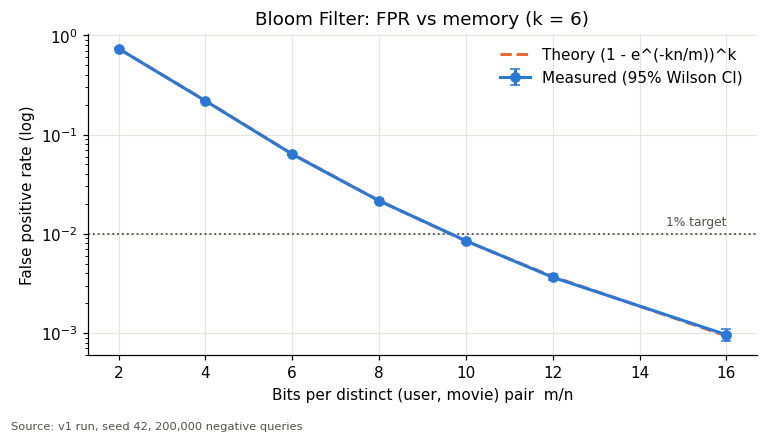

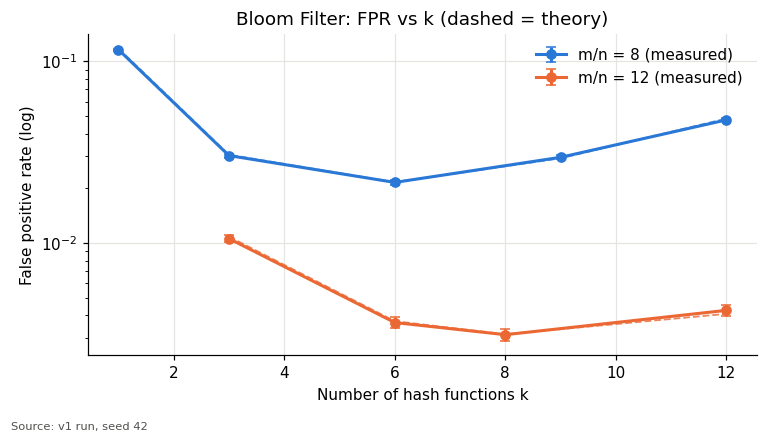

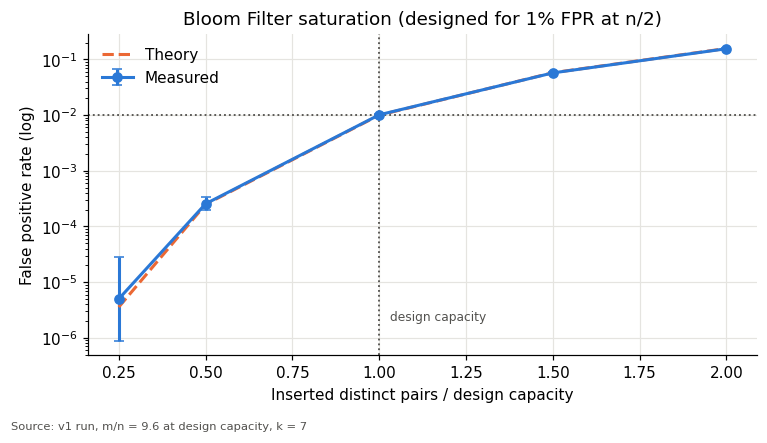

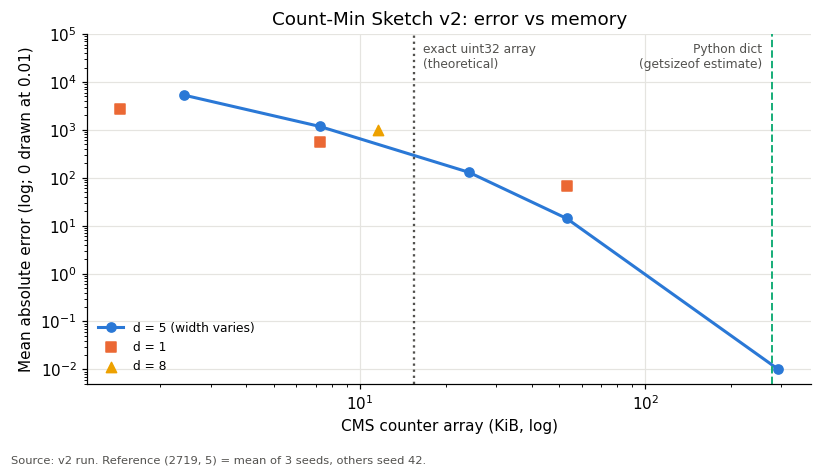

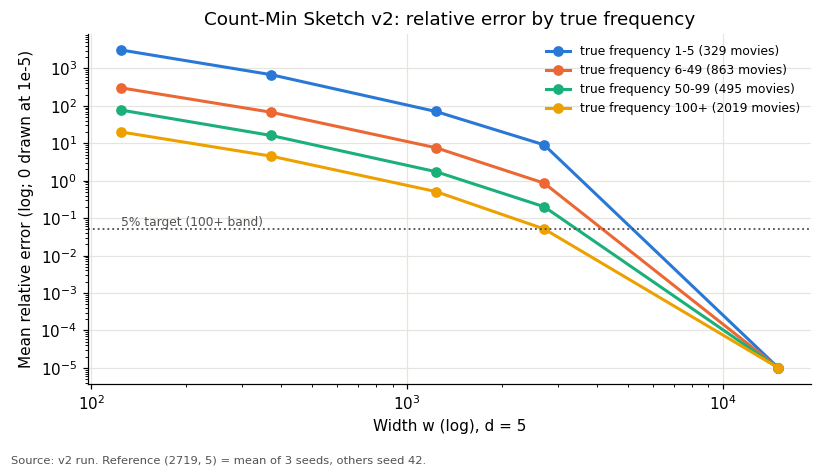

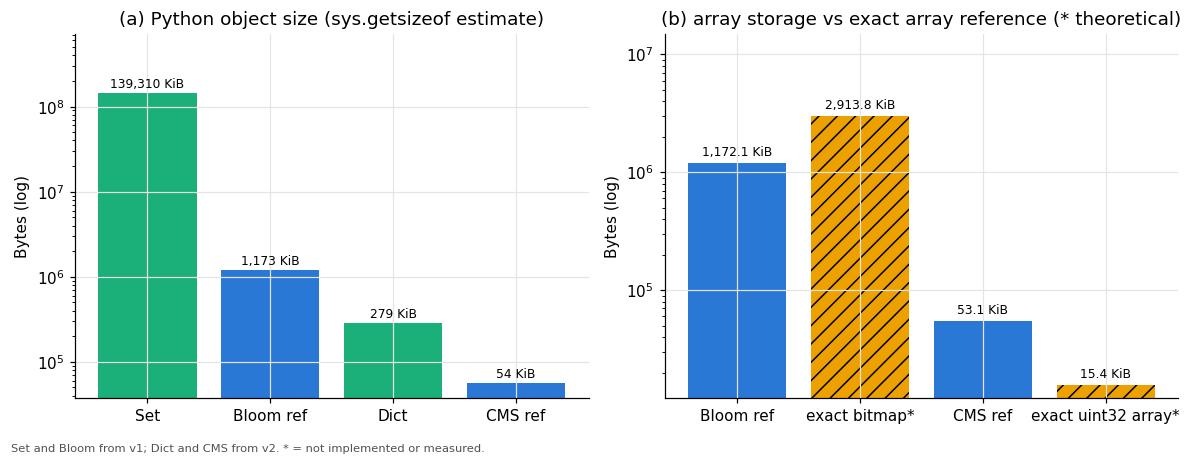

[STEP 7] 그래프 6개 저장: results_movielens_final/figures


In [12]:
import matplotlib
if 'ipykernel' not in sys.modules: matplotlib.use('Agg')
import matplotlib.pyplot as plt
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']; GREY = '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 170, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e5e4e0', 'lines.linewidth': 2, 'legend.frameon': False, 'font.size': 10})
FIG = FINAL_DIR / 'figures'
def finish(name, note):
    plt.gcf().text(0.01, 0.005, note, fontsize=7.5, color=GREY, ha='left', va='bottom')
    plt.tight_layout(rect=(0, 0.035, 1, 1)); plt.savefig(FIG / name, bbox_inches='tight')
    if 'ipykernel' in sys.modules: plt.show()
    plt.close()
def ci_err(rows):
    return [[r['fpr'] - r['fpr_ci_low'] for r in rows], [r['fpr_ci_high'] - r['fpr'] for r in rows]]

# 1 Bloom FPR vs m/n
a = sorted([r for r in V1_BLOOM42 if r['k'] == 6], key=lambda r: r['m'])
plt.figure(figsize=(7, 4))
plt.errorbar([r['bits_per_key'] for r in a], [r['fpr'] for r in a], yerr=ci_err(a), fmt='o-', color=C[0], capsize=3, label='Measured (95% Wilson CI)')
plt.plot([r['bits_per_key'] for r in a], [r['theory_fpr'] for r in a], '--', color=C[1], label='Theory (1 - e^(-kn/m))^k')
plt.axhline(FPR_TARGET, color=GREY, ls=':', lw=1.2); plt.text(a[-1]['bits_per_key'], FPR_TARGET * 1.2, '1% target', ha='right', fontsize=8, color=GREY)
plt.yscale('log'); plt.xlabel('Bits per distinct (user, movie) pair  m/n'); plt.ylabel('False positive rate (log)')
plt.title('Bloom Filter: FPR vs memory (k = 6)'); plt.legend()
finish('1_bloom_fpr_vs_bits.png', 'Source: v1 run, seed 42, 200,000 negative queries')

# 2 Bloom FPR vs k
plt.figure(figsize=(7, 4))
for c, b in zip(C, (8, 12)):
    a = sorted([r for r in V1_BLOOM42 if abs(r['bits_per_key'] - b) < 0.01], key=lambda r: r['k'])
    plt.errorbar([r['k'] for r in a], [r['fpr'] for r in a], yerr=ci_err(a), fmt='o-', color=c, capsize=3, label=f'm/n = {b} (measured)')
    plt.plot([r['k'] for r in a], [r['theory_fpr'] for r in a], '--', color=c, lw=1.2, alpha=0.8)
plt.yscale('log'); plt.xlabel('Number of hash functions k'); plt.ylabel('False positive rate (log)')
plt.title('Bloom Filter: FPR vs k (dashed = theory)'); plt.legend()
finish('2_bloom_fpr_vs_k.png', 'Source: v1 run, seed 42')

# 3 Bloom 포화
plt.figure(figsize=(7, 4))
x = [r['load_ratio'] for r in V1_SAT]; y = [max(r['fpr'], 1e-6) for r in V1_SAT]
plt.errorbar(x, y, yerr=[[yy - max(r['fpr_ci_low'], 1e-7) for yy, r in zip(y, V1_SAT)], [r['fpr_ci_high'] - r['fpr'] for r in V1_SAT]],
             fmt='o-', color=C[0], capsize=3, label='Measured')
plt.plot(x, [r['theory_fpr'] for r in V1_SAT], '--', color=C[1], label='Theory')
plt.axvline(1, color=GREY, ls=':', lw=1.2); plt.axhline(FPR_TARGET, color=GREY, ls=':', lw=1.2)
plt.text(1.03, 2e-6, 'design capacity', fontsize=8, color=GREY)
plt.yscale('log'); plt.xlabel('Inserted distinct pairs / design capacity'); plt.ylabel('False positive rate (log)')
plt.title('Bloom Filter saturation (designed for 1% FPR at n/2)'); plt.legend()
finish('3_bloom_saturation.png', 'Source: v1 run, m/n = 9.6 at design capacity, k = 7')

# 4 CMS 오차 vs 메모리
FLOOR = 0.01
d5 = sorted([e for e in cms_sum if e['d'] == 5], key=lambda e: e['w'])
others = [e for e in cms_sum if e['d'] != 5]
plt.figure(figsize=(7.5, 4.3))
plt.plot([e['payload_bytes'] / 1024 for e in d5], [max(e['mae'], FLOOR) for e in d5], 'o-', color=C[0], label='d = 5 (width varies)')
for mk, dd, c in (('s', 1, C[1]), ('^', 8, C[3])):
    pts = [e for e in others if e['d'] == dd]
    plt.scatter([e['payload_bytes'] / 1024 for e in pts], [max(e['mae'], FLOOR) for e in pts], marker=mk, s=45, color=c, zorder=3, label=f'd = {dd}')
plt.axvline(DICT_DEEP / 1024, color=C[2], ls='--', lw=1.3)
plt.text(DICT_DEEP / 1024 * 0.92, 2e4, 'Python dict\n(getsizeof estimate)', ha='right', fontsize=8, color=GREY)
plt.axvline(dense_ref / 1024, color=GREY, ls=':', lw=1.5)
plt.text(dense_ref / 1024 * 1.08, 2e4, 'exact uint32 array\n(theoretical)', ha='left', fontsize=8, color=GREY)
plt.xscale('log'); plt.yscale('log'); plt.ylim(FLOOR * 0.5, 1e5)
plt.xlabel('CMS counter array (KiB, log)'); plt.ylabel(f'Mean absolute error (log; 0 drawn at {FLOOR})')
plt.title('Count-Min Sketch v2: error vs memory'); plt.legend(loc='lower left', fontsize=8)
finish('4_cms_error_vs_memory.png', 'Source: v2 run. Reference (2719, 5) = mean of 3 seeds, others seed 42.')

# 5 CMS 빈도 구간별 상대오차 (d = 5)
plt.figure(figsize=(7.5, 4.3))
for c, (lab, _, _) in zip(C, BANDS):
    pts = sorted((b['w'], b['mean_relative_error']) for b in band_summary if b['d'] == 5 and b['frequency_band'] == lab and b['mean_relative_error'] is not None)
    if not pts: continue
    items = next(b['items'] for b in band_summary if b['frequency_band'] == lab)
    plt.plot([p[0] for p in pts], [max(p[1], 1e-5) for p in pts], 'o-', color=c, label=f'true frequency {lab} ({items} movies)')
plt.axhline(CMS_HIGH_FREQ_RE_TARGET, color=GREY, ls=':', lw=1.2)
plt.text(d5[0]['w'], CMS_HIGH_FREQ_RE_TARGET * 1.25, '5% target (100+ band)', fontsize=8, color=GREY)
plt.xscale('log'); plt.yscale('log'); plt.xlabel('Width w (log), d = 5'); plt.ylabel('Mean relative error (log; 0 drawn at 1e-5)')
plt.title('Count-Min Sketch v2: relative error by true frequency'); plt.legend(fontsize=8)
finish('5_cms_error_by_frequency.png', 'Source: v2 run. Reference (2719, 5) = mean of 3 seeds, others seed 42.')

# 6 메모리 비교 (두 기준)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
lab_a = ['Set', 'Bloom ref', 'Dict', 'CMS ref']
val_a = [V1_BASELINE['Set']['deep_bytes'], bref['deep_bytes'], DICT_DEEP, cref['deep_bytes']]
bars = axes[0].bar(lab_a, val_a, color=[C[2], C[0], C[2], C[0]])
for bar, v in zip(bars, val_a): axes[0].text(bar.get_x() + bar.get_width() / 2, v * 1.15, f'{v / 1024:,.0f} KiB', ha='center', fontsize=8)
axes[0].set_yscale('log'); axes[0].set_ylim(top=max(val_a) * 5); axes[0].set_ylabel('Bytes (log)'); axes[0].set_title('(a) Python object size (sys.getsizeof estimate)')
lab_b = ['Bloom ref', 'exact bitmap*', 'CMS ref', 'exact uint32 array*']
val_b = [bref['payload_bytes'], bitmap_ref, cref['payload_bytes'], dense_ref]
bars = axes[1].bar(lab_b, val_b, color=[C[0], C[3], C[0], C[3]])
for bar, v, lab in zip(bars, val_b, lab_b):
    if lab.endswith('*'): bar.set_hatch('//')
    axes[1].text(bar.get_x() + bar.get_width() / 2, v * 1.15, f'{v / 1024:,.1f} KiB', ha='center', fontsize=8)
axes[1].set_yscale('log'); axes[1].set_ylim(top=max(val_b) * 5); axes[1].set_ylabel('Bytes (log)'); axes[1].set_title('(b) array storage vs exact array reference (* theoretical)')
finish('6_memory_comparison.png', 'Set and Bloom from v1; Dict and CMS from v2. * = not implemented or measured.')
print('[STEP 7] 그래프 6개 저장:', FIG)

## STEP 8 — 결과 출처 문서와 새 ZIP

In [13]:
(FINAL_DIR / 'PROVENANCE.md').write_text(f"""# 결과 출처 (MovieLens 1M, 과제 4)

- 데이터: {URL}  (SHA-256 {info['sha256']}, v1과 같은 파일: {info['same_file_as_v1']})
- v1 실행: 1차 노트북. 원본 결과는 `archive_v1/`에 수정 없이 보관. CMS v1(선형 해시) 결과는 보관만 하며 본 결과에 사용하지 않음.
- v2 실행: 이 노트북. CPU {ENV.get('cpu_model')}, RAM {ENV.get('ram_gb')} GB (`environment_v2.json`).

| 파일 | 내용 | 출처 |
|---|---|---|
| bloom_v1.csv, bloom_summary_v1.csv, bloom_v1_fpr_overview.csv | Bloom 정확도·파라미터 15개 | v1 |
| bloom_saturation_v1.csv | Bloom 포화 실험 | v1 |
| timing_v1_bloom_set.csv | Bloom·Set 처리시간 (같은 v1 런타임) | v1 |
| cms_v2.csv, cms_v2_frequency_bands.csv | CMS v2 원자료 (설정·시드별) | v2 |
| cms_v2_summary.csv, cms_v2_equal_memory.csv, cms_v2_depth_effect.csv, cms_v2_frequency_band_summary.csv | CMS v2 요약 | v2 |
| cms_hash_collision_check.csv, cms_prehash_injectivity.json | CMS 해시 검증 | v2 |
| baseline_v2.json, timing_v2_cms_dictionary.csv | 파싱·Dictionary·CMS 처리시간 (같은 v2 런타임) | v2 |
| memory_comparison.csv | getsizeof 추정 / 배열 저장 공간 / tracemalloc(v1만) / 이론 참고값 구분 | v1 + v2 + 계산 |
| decision_summary_final.json | 판정 요약 | v1 + v2 |
| figures/ | 핵심 그래프 6개 | v1 + v2 |

- 서로 다른 런타임의 처리시간은 직접 비교하지 않는다.
- CMS 대표 설정 (2719, 5)만 시드 3개, 시간 3회 측정. 나머지 8개는 시드 42, 시간 1회 측정(탐색적 비교용).
- 판정 기준(Bloom FPR 1%, CMS 고빈도 상대오차 5%·Top-100 95%)은 실험용 가정이며 산업 표준이 아니다.
""", encoding='utf-8')
if FINAL_ZIP.exists(): FINAL_ZIP.unlink()
with zipfile.ZipFile(FINAL_ZIP, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in sorted(FINAL_DIR.rglob('*')):
        if p.is_file(): z.write(p, arcname=str(p.relative_to(FINAL_DIR.parent)))
print(f'[STEP 8] 새 결과 ZIP: {FINAL_ZIP.resolve()} ({FINAL_ZIP.stat().st_size / 1024:,.0f} KiB), 총 {elapsed()}')
print('기존 결과 ZIP은 수정하지 않음:', V1_ZIP.resolve())
try:
    from google.colab import files
    files.download(str(FINAL_ZIP))
except ImportError:
    pass

[STEP 8] 새 결과 ZIP: /content/movielens_results_final.zip (901 KiB), 총   3.3분
기존 결과 ZIP은 수정하지 않음: /content/movielens_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>